# 31 Which NaI did Zhu et al. sum?

Under Zhu et al.'s rule as written (notebook 23), GRB 230307A has no precursor in my run. With the catalogue's detector (na alone), the gap
between the precursor and the main emission isn't quiet enough (below 3 sigma per bin), while Zhu et al. give it 3.15. The rule doesn't
change. What changes is the light curve it reads, and the paper doesn't say which NaI were summed. The zhu package uses the NaI of the GBM
catalogue's spectral fit (for all but four bursts), and the closest NaI within 60 degrees (at most three) where the catalogue has no fit.

Here every complete burst of the sample is run again under four choices of NaI, with the same bin, background and rule as the committed
run (episodes only, and the committed results aren't touched):
- catalogue: the committed run;
- brightest three: the three NaI with the most net counts over the square root of the background in the burst's own main emission (64 ms
  bins);
- closest three: the three NaI at the smallest angles to the burst (DET_ANG of each detector's response at the burst);
- closest within 60 deg: the same, but only those within 60 degrees (the package's rule for bursts without a catalogue fit).

Each is scored on how many of Zhu et al.'s Table 1 durations it gives within 0.2 dex (a factor of 1.6), the measure notebook 23 uses.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from grbtool.bursts import DATA_ROOT, _angle
from zhu import RESULTS
from zhu.background import light_curve
from zhu.catalogue import data_name
from zhu.episodes import blocks_of, find_episodes
from zhu.io import states
from zhu.run import read_sample, start_burst

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
NAI = [f"n{i:x}" for i in range(12)]
CACHE = Path("results/checks/nai_choice.csv")
EPISODES = (("pe", "PE"), ("qe1", "QE1"), ("me", "ME"), ("we", "WE"))
sample = read_sample()
complete = sample.index[states(sample.index, RESULTS).status == "complete"]
zhu = pd.read_csv("shared/zhu2026_table1.csv", comment="#", dtype={"GRB": str}).set_index("GRB")
print(len(complete), "complete bursts of", len(sample))

110 complete bursts of 111


In [2]:
def brightest(burst, span):
    """The NaI by net counts over the square root of the background in span (64 ms bins)."""
    snr = {}
    for det in NAI:
        try:
            lc = light_curve(burst, 0.064, span=span, detectors=[det])
        except Exception:
            continue
        snr[det] = (lc.counts.sum() - lc.background.sum()) / np.sqrt(max(lc.background.sum(), 1.0))
    return sorted(snr, key=lambda d: -snr[d])


def angle(folder, trigger, det):
    try:
        return _angle(folder, trigger, det)
    except KeyError:                    # a response without DET_ANG (GRB 100116A's)
        return None


def closest(name, trigger):
    folder = DATA_ROOT / data_name(name, DATA_ROOT) / "current"
    angles = {d: angle(folder, trigger, d) for d in NAI}
    return sorted([d for d, a in angles.items() if a is not None], key=lambda d: angles[d]), angles


def durations(found):
    return {label: (getattr(found, key)[1] - getattr(found, key)[0]) if getattr(found, key) else np.nan for key, label in EPISODES}


def one(name, trigger):
    """The zhu2026 episodes of one burst under each choice of NaI, on the committed run's bin and background."""
    record = json.loads((RESULTS / name / "episodes.json").read_text())
    committed = record["modes"]["zhu2026"]
    out = dict(name=name, catalogue=" ".join(record["nai"]))
    out.update({f"T100_{label}_catalogue": (committed[key][1] - committed[key][0]) if committed.get(key) else np.nan for key, label in EPISODES})
    if not committed.get("me"):
        return out
    burst, _ = start_burst(name, trigger)
    burst.bkg_windows, burst.bkg_order = [tuple(w) for w in record["bkg_windows"]], record["bkg_order"]
    order, angles = closest(name, trigger)
    sets = {"brightest3": brightest(burst, tuple(committed["me"]))[:3], "closest3": order[:3],
            "closest60": [d for d in order if angles[d] < 60.0][:3]}
    out["angles"] = " ".join(f"{d}:{angles[d]:.0f}" for d in order[:5])
    for variant, dets in sets.items():
        out[f"detectors_{variant}"] = " ".join(dets)
        if sorted(dets) == sorted(record["nai"]):
            out.update({f"T100_{label}_{variant}": out[f"T100_{label}_catalogue"] for _, label in EPISODES})
        elif dets:
            lc = light_curve(burst, record["Tres"], detectors=dets)
            out.update({f"T100_{label}_{variant}": v for label, v in durations(find_episodes(lc, blocks_of(lc), mode="zhu2026", burst=name)).items()})
    return out


if CACHE.exists():
    t = pd.read_csv(CACHE, dtype={"name": str}).set_index("name")
else:
    rows = []
    for name in complete:
        try:
            rows.append(one(name, sample.loc[name, "trigger"]))
        except Exception as error:
            rows.append(dict(name=name, note=f"{type(error).__name__}: {error}"[:200]))
    t = pd.DataFrame(rows).set_index("name")
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    t.to_csv(CACHE)
print(len(t), "bursts;", t.note.dropna().to_dict() if "note" in t else "no failures")

110 bursts; {'100116A': 'its responses have no DET_ANG, so no angle choice'}


## 1. The four choices against Zhu et al.'s Table 1

In [3]:
VARIANTS = {"catalogue": "catalogue", "brightest3": "brightest three", "closest3": "closest three", "closest60": "closest within 60 deg"}
t = t.join(zhu[[f"T100_{e}" for _, e in EPISODES]].add_suffix("_zhu"))
rows = []
for v, label in VARIANTS.items():
    row = {"NaI": label, "precursors found": int(t[f"T100_PE_{v}"].notna().sum())}
    for _, e in EPISODES:
        ours, theirs = t[f"T100_{e}_{v}"], t[f"T100_{e}_zhu"]
        both = ours.notna() & theirs.notna() & (ours > 0) & (theirs > 0)
        within = np.abs(np.log10(ours[both] / theirs[both])) <= 0.2
        row[f"{e} within 0.2 dex"] = f"{int(within.sum())}/{int(both.sum())}"
    row["precursor exactly theirs"] = int((np.abs(t[f"T100_PE_{v}"] - t.T100_PE_zhu) < 0.0015).sum())
    rows.append(row)
score = pd.DataFrame(rows).set_index("NaI")
print(score.to_string())
same = t.detectors_closest3.fillna("").str.split().apply(sorted) == t.catalogue.fillna("").str.split().apply(sorted)
print(f"the catalogue's NaI are the three closest in {int(same.sum())} of {len(t)} bursts")
for v in ("brightest3", "closest3"):
    ran = t[f"detectors_{v}"].fillna("") != ""
    flips = t.index[ran & (t.T100_PE_catalogue.isna() != t[f"T100_PE_{v}"].isna())]
    print(f"precursor found by one of catalogue and {VARIANTS[v]} but not the other: {len(flips)}", sorted(flips))

                       precursors found PE within 0.2 dex QE1 within 0.2 dex ME within 0.2 dex WE within 0.2 dex  precursor exactly theirs
NaI                                                                                                                                       
catalogue                            96             75/96              86/96            79/110            91/110                        27
brightest three                      97             72/97              84/97            79/110            89/110                        22
closest three                        97             76/97              85/97            82/109            94/109                        24
closest within 60 deg                95             75/95              84/95            79/109            93/109                        27
the catalogue's NaI are the three closest in 71 of 110 bursts
precursor found by one of catalogue and brightest three but not the other: 7 ['131216A', '140329A', '160

The scores are on the same bursts, so the fair comparison is paired: how many bursts each choice brings within 0.2 dex of Zhu et al.
that the catalogue's NaI don't, against how many it loses, with a two-sided sign test.

In [4]:
from scipy.stats import binomtest


def within(v, e):
    ours, theirs = t[f"T100_{e}_{v}"], t[f"T100_{e}_zhu"]
    ok = ours.notna() & theirs.notna() & (ours > 0) & (theirs > 0)
    return (np.abs(np.log10(ours.where(ok) / theirs.where(ok))) <= 0.2) & ok


rows = []
for v in ("brightest3", "closest3", "closest60"):
    ran = t[f"detectors_{v}"].fillna("") != ""
    for _, e in EPISODES:
        a, b = within("catalogue", e)[ran], within(v, e)[ran]
        gained, lost = int((b & ~a).sum()), int((a & ~b).sum())
        p = binomtest(gained, gained + lost).pvalue if gained + lost else 1.0
        rows.append(dict(NaI=VARIANTS[v], episode=e, cell=f"+{gained} -{lost} (p {p:.2f})"))
print("bursts brought within 0.2 dex (+) and lost (-) against the catalogue's NaI, with the sign test's p:")
print(pd.DataFrame(rows).pivot(index="NaI", columns="episode", values="cell")[[e for _, e in EPISODES]].to_string())

bursts brought within 0.2 dex (+) and lost (-) against the catalogue's NaI, with the sign test's p:
episode                            PE             QE1              ME              WE
NaI                                                                                  
brightest three        +3 -6 (p 0.51)  +4 -6 (p 0.75)  +3 -3 (p 1.00)  +2 -4 (p 0.69)
closest three          +6 -4 (p 0.75)  +4 -4 (p 1.00)  +6 -2 (p 0.29)  +5 -1 (p 0.22)
closest within 60 deg  +3 -2 (p 1.00)  +2 -3 (p 1.00)  +3 -2 (p 1.00)  +4 -1 (p 0.38)


No choice of NaI matches Zhu et al.'s table better than the catalogue's. The scores differ by one to three bursts, and burst by burst the
gains and losses are about the same size (a sign-test p of 0.2 or more for every duration), so the committed run keeps the catalogue's NaI.
The choice does decide whether a weak precursor is found, though. In 6 or 7 of the 110 bursts the rule finds a precursor with one choice and
not with the other, about 6%, which is a systematic on whether a faint precursor counts. GRB 190810A is one of them: with its three closest
NaI (here also the three brightest) its precursor and gap are exactly Zhu et al.'s, 0.012 and 0.040 s, and with the catalogue's two there is
none.

## 2. GRB 230307A

The same rule on GRB 230307A's light curve summed over different NaI, with the block in the middle of the gap (at 0.62 s from the trigger)
and its mean excess per bin. Its detectors at the burst: na at 51 deg, nb at 62 and n2 at 85. n6, n0 and n7, the next brightest after na,
are at 134, 137 and 119 deg, and they're only lit because the burst is so bright, while na loses counts to pile-up (notebook 12).

In [5]:
name = "230307A"
record = json.loads((RESULTS / name / "episodes.json").read_text())
burst, _ = start_burst(name, sample.loc[name, "trigger"])
burst.bkg_windows, burst.bkg_order = [tuple(w) for w in record["bkg_windows"]], record["bkg_order"]
sets = {"na (catalogue)": ["na"], "na nb (within 60 deg)": ["na", "nb"], "na nb n2 (closest three)": ["na", "nb", "n2"],
        "na n6 (brightest two)": ["na", "n6"], "na n6 n0 (brightest three)": ["na", "n6", "n0"], "na n6 n7": ["na", "n6", "n7"],
        "na nb n2 n6 n7": ["na", "nb", "n2", "n6", "n7"], "all twelve": NAI}
rows = []
for label, dets in sets.items():
    lc = light_curve(burst, record["Tres"], detectors=dets)
    blocks = blocks_of(lc)
    found = find_episodes(lc, blocks, mode="zhu2026", burst=name)
    gap = blocks[(blocks.start <= 0.62) & (blocks.stop > 0.62)].iloc[0]
    rows.append({"NaI": label, **{k: round(v, 3) for k, v in durations(found).items()},
                 "block at 0.62 s": f"{gap.start:.3f}-{gap.stop:.3f} s", "sigma per bin": round(float(gap.snr_bin), 2)})
rows.append({"NaI": "Zhu et al.", **{e: zhu.loc[name, f"T100_{e}"] for _, e in EPISODES}, "block at 0.62 s": "", "sigma per bin": 3.15})
gap_table = pd.DataFrame(rows).set_index("NaI")
gap_table.to_csv("results/checks/gap_230307A_by_nai.csv")
print(gap_table.to_string())

                               PE    QE1      ME       WE block at 0.62 s  sigma per bin
NaI                                                                                     
na (catalogue)                NaN    NaN  18.100  131.652   0.556-0.704 s           4.20
na nb (within 60 deg)         NaN    NaN  18.100  130.984   0.540-0.704 s           3.29
na nb n2 (closest three)    0.560  0.164  17.408  106.040   0.540-0.704 s           2.90
na n6 (brightest two)         NaN    NaN  18.100  132.588   0.556-0.704 s           3.63
na n6 n0 (brightest three)    NaN    NaN  18.100  130.344   0.540-0.704 s           3.35
na n6 n7                      NaN    NaN  18.124  132.568   0.556-0.704 s           3.19
na nb n2 n6 n7              0.556  0.164  17.408  131.328   0.540-0.704 s           2.86
all twelve                  0.568  0.164  17.328  136.224   0.540-0.704 s           2.16
Zhu et al.                  0.576  0.152  17.372  132.580                           3.15


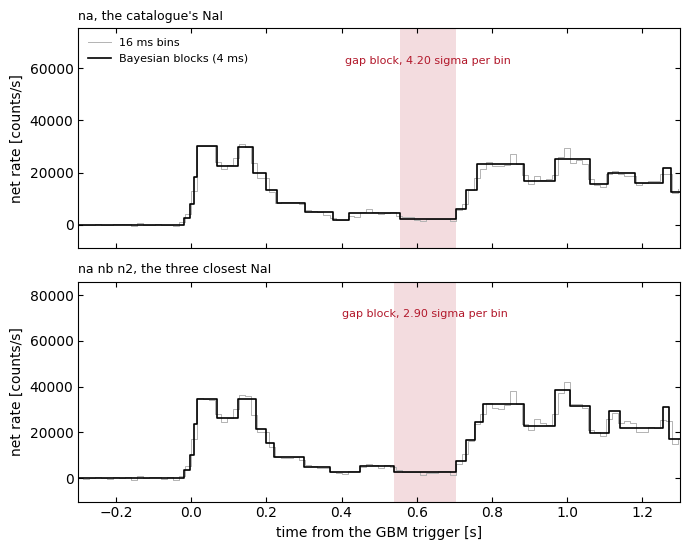

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(7.0, 5.6), sharex=True)
for ax, (label, dets) in zip(axes, (("na, the catalogue's NaI", ["na"]), ("na nb n2, the three closest NaI", ["na", "nb", "n2"]))):
    lc = light_curve(burst, record["Tres"], detectors=dets)
    blocks = blocks_of(lc)
    k = 4                                                   # drawn in bins of 16 ms
    n = (len(lc.counts) // k) * k
    left = lc.edges[:n:k]
    net = (lc.counts[:n] - lc.background[:n]).reshape(-1, k).sum(1) / (k * lc.tres)
    show = (left >= -0.3) & (left <= 1.3)
    b = blocks[(blocks.stop > -0.3) & (blocks.start < 1.3)]
    top = 2.5 * b[(b.start >= -0.1) & (b.stop <= 0.5)].rate.max()     # the precursor's scale; the main emission runs off the top
    ax.step(left[show], net[show], where="post", color="0.7", lw=0.7, label="16 ms bins")
    ax.step(np.r_[b.start, b.stop.iloc[-1]], np.r_[b.rate, b.rate.iloc[-1]], where="post", color="k", lw=1.2, label="Bayesian blocks (4 ms)")
    gap = blocks[(blocks.start <= 0.62) & (blocks.stop > 0.62)].iloc[0]
    ax.axvspan(gap.start, gap.stop, color="#b2182b", alpha=0.15, lw=0)
    ax.text(0.5 * (gap.start + gap.stop), 0.86 * top, f"gap block, {gap.snr_bin:.2f} sigma per bin", ha="center", va="top", fontsize=8, color="#b2182b")
    ax.set(ylim=(-0.12 * top, top), ylabel="net rate [counts/s]")
    ax.set_title(label, fontsize=9, loc="left")
    ax.tick_params(which="both", direction="in", top=True, right=True)
axes[0].legend(fontsize=8, frameon=False, loc="upper left")
axes[1].set(xlabel="time from the GBM trigger [s]", xlim=(-0.3, 1.3))
fig.tight_layout(); fig.savefig("figures/31_gap_230307A.png", dpi=150); plt.show()

The block in the middle of GRB 230307A's gap (0.54-0.70 s) is at 2.2-4.2 sigma per bin depending on the NaI summed, on either side of the
rule's 3 (Zhu et al. give 3.15). With the catalogue's na alone (4.20, as in notebook 23), na with nb, or the brightest NaI it's above 3, and
the rule finds no precursor. With the three closest NaI (na nb n2) it's 2.90, and the rule gives Zhu et al.'s precursor, gap and main
emission to within 16, 12 and 36 ms. But then the whole emission ends at 106 s instead of 132.6 s, because n2, at 85 degrees, adds more
background than signal in the faint tail. Adding n6 and n7, which are bright in the tail, gives all four durations (0.556, 0.164, 17.408 and
131.3 s against 0.576, 0.152, 17.372 and 132.58). I found that set by trying, so it shows the numbers can be reproduced, not that it's what
Zhu et al. used.

What it does show is that GRB 230307A's precursor is a precursor under this rule only just: whether its gap counts as quiet depends on
detectors the paper doesn't name. The precursor itself isn't in doubt (Dichiara et al. find it with their own method, and its E_peak is
far below the main emission's, notebook 12). It's the rule's verdict on it that's marginal. Nothing downstream changes, because the joint
analysis of GRB 230307A uses Dichiara et al.'s windows, not the rule's.